In [1]:
!pip install pymorphy3 pymorphy3-dicts-ru -q

In [2]:
from google.colab import files
uploaded = files.upload()

Saving samara_university_august_2026.csv to samara_university_august_2026.csv


In [49]:
import pandas as pd
import numpy as np
import re
import json
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# Загрузка CSV, собранного в ЛР1
df = pd.read_csv('samara_university_august_2026.csv')

print("Размер датасета:", df.shape)
print("Колонки:", list(df.columns))

Размер датасета: (40, 9)
Колонки: ['id', 'owner_id', 'url', 'date', 'text', 'likes', 'comments', 'reposts', 'views']


In [50]:
# Убираем посты без текста и дубликаты
df_clean = df.copy()
df_clean = df_clean.dropna(subset=['text'])
df_clean = df_clean[df_clean['text'].astype(str).str.strip() != '']
df_clean = df_clean.drop_duplicates(subset=['text'])

print(f"Было постов: {len(df)}, осталось после удаления пустых и дубликатов: {len(df_clean)}")


def clean_text(text: str) -> str:
    """Очистка текста поста: ссылки, VK-упоминания, спецсимволы, лишние пробелы."""
    text = str(text)
    # VK-разметка ссылок, оставляем подпись
    text = re.sub(r'\[https?://[^\|\]]+\|([^\]]+)\]', r'\1', text)
    # Обычные URL
    text = re.sub(r'https?://\S+', ' ', text)
    # VK-упоминания @id123
    text = re.sub(r'@\w+', ' ', text)
    # Эмодзи и прочие не-буквы (оставляем русские/латинские буквы, цифры, пробелы)
    text = re.sub(r'[^а-яА-ЯёЁa-zA-Z0-9\s]', ' ', text)
    # Схлопываем пробелы
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


df_clean['clean_text'] = df_clean['text'].apply(clean_text)
df_clean = df_clean[df_clean['clean_text'].str.len() > 0]

print(f"Осталось постов после очистки: {len(df_clean)}")

Было постов: 40, осталось после удаления пустых и дубликатов: 39
Осталось постов после очистки: 39


In [51]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

import pymorphy3

morph = pymorphy3.MorphAnalyzer()
lemmatize = lambda w: morph.parse(w)[0].normal_form

# стоп-слова
ru_stop = set(stopwords.words('russian'))
extra_stop = {'наш', 'который', 'это', 'также', 'свой', 'год'}

STOPWORDS = {lemmatize(w) for w in (ru_stop | extra_stop)}

def tokenize_lemmatize(text: str):
    tokens = text.split()
    lemmas = []
    for t in tokens:
        if len(t) <= 2 or t.isdigit():
            continue
        lemma = lemmatize(t)
        if lemma in STOPWORDS:
            continue
        lemmas.append(lemma)
    return lemmas

df_clean['tokens'] = df_clean['clean_text'].apply(tokenize_lemmatize)

print("Пример токенов:", df_clean['tokens'].iloc[0][:15])
print("Средняя длина поста в токенах:", round(df_clean['tokens'].apply(len).mean(), 1))

Пример токенов: ['научный', 'коллектив', 'университет', 'значимый', 'результат', 'останавливаться', 'достигнутый', 'сегодня', 'заседание', 'учёный', 'совет', 'ректор', 'владимир', 'богатырёв', 'представить']
Средняя длина поста в токенах: 94.0


In [55]:
# Считаем частоту лемм по всему корпусу
all_tokens = [tok for tokens in df_clean['tokens'] for tok in tokens]
word_counts = Counter(all_tokens)

# Сохраняем в CSV
wc_df = pd.DataFrame(word_counts.most_common(), columns=['word', 'count'])
wc_df.to_csv('wordcount.csv', index=False, encoding='utf-8-sig')

print(f"Уникальных слов: {len(wc_df)}")
print("\nТОП-30 слов:")
print(wc_df.head(30).to_string(index=False))

Уникальных слов: 1794

ТОП-30 слов:
        word  count
 университет     87
   самарский     47
     студент     36
      проект     27
   программа     24
     королёв     23
    институт     23
       новый     22
      регион     17
       центр     16
    развитие     15
 космический     15
студенческий     15
     область     15
      россия     14
       стать     14
       наука     14
     человек     14
  управление     13
    участник     13
      работа     12
   факультет     12
        сайт     11
      страна     11
     кафедра     11
 образование     10
 авиационный     10
     аппарат     10
         сад     10
     история     10


In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Для TF-IDF передаём уже лемматизированные токены, склеенные обратно в строку
df_clean['lemmas_joined'] = df_clean['tokens'].apply(lambda toks: ' '.join(toks))

vectorizer = TfidfVectorizer(
    max_features=300,       # ограничение на количество признаков
    min_df=2,               # слово должно встречаться минимум в 2 документах
    max_df=0.9,             # игнорируем слова, встречающиеся более чем в 90% документов
    ngram_range=(1, 1)      # униграммы + биграммы
)

X = vectorizer.fit_transform(df_clean['lemmas_joined'])
print("Размер TF-IDF матрицы:", X.shape)

Размер TF-IDF матрицы: (39, 300)


In [57]:
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np
import pandas as pd

K_RANGE = range(2, 11)
MIN_CLUSTER_SIZE = 2

# Собираем метрики по всем k и алгоритмам
rows = []
for k in K_RANGE:
    for algo in ['KMeans', 'MiniBatchKMeans', 'Agglomerative']:
        if algo == 'KMeans':
            labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        elif algo == 'MiniBatchKMeans':
            labels = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        else:
            labels = AgglomerativeClustering(n_clusters=k).fit_predict(X.toarray())

        sil = silhouette_score(X, labels, metric='cosine')
        db  = davies_bouldin_score(X.toarray(), labels)
        min_size = np.bincount(labels).min()

        rows.append({
            'k': k,
            'algorithm': algo,
            'silhouette': round(sil, 4),
            'davies_bouldin': round(db, 4),
            'min_cluster_size': min_size,
        })

df_k = pd.DataFrame(rows)

# Выбор k: максимум силуэта KMeans среди разбиений без мелких кластеров
kmeans_df = df_k[df_k['algorithm'] == 'KMeans']
allowed = kmeans_df[kmeans_df['min_cluster_size'] >= MIN_CLUSTER_SIZE]
BEST_K = int(allowed.loc[allowed['silhouette'].idxmax(), 'k'])

print(f"Оптимальное число кластеров: {BEST_K}")
print("\nМетрики по всем k (KMeans):")
print(kmeans_df.to_string(index=False))
print("\nСравнение алгоритмов при BEST_K:")
print(df_k[df_k['k'] == BEST_K].to_string(index=False))

df_k.to_csv('k_selection_metrics.csv', index=False, encoding='utf-8-sig')

Оптимальное число кластеров: 8

Метрики по всем k (KMeans):
 k algorithm  silhouette  davies_bouldin  min_cluster_size
 2    KMeans      0.0358          4.3918                11
 3    KMeans      0.0375          3.8506                 6
 4    KMeans      0.0312          3.5869                 4
 5    KMeans      0.0463          3.1807                 5
 6    KMeans      0.0464          2.8588                 4
 7    KMeans      0.0737          2.6171                 2
 8    KMeans      0.0882          2.4479                 3
 9    KMeans      0.0825          2.3329                 2
10    KMeans      0.0824          2.0832                 1

Сравнение алгоритмов при BEST_K:
 k       algorithm  silhouette  davies_bouldin  min_cluster_size
 8          KMeans      0.0882          2.4479                 3
 8 MiniBatchKMeans     -0.0237          2.1838                 1
 8   Agglomerative      0.0963          2.4308                 2


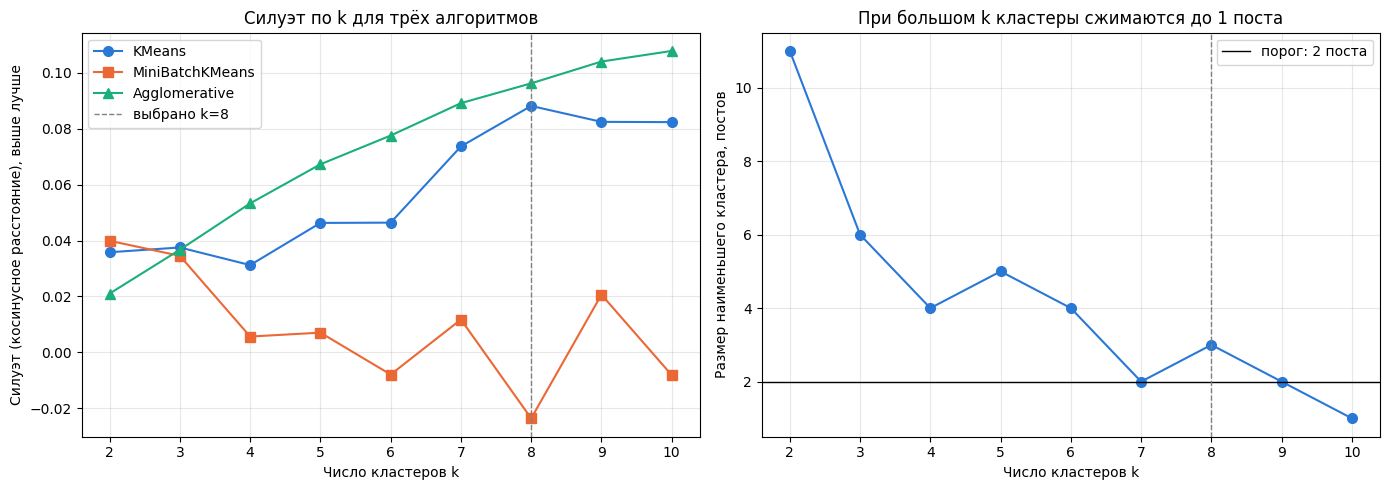

In [58]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Силуэт по k для трёх алгоритмов
for algo, marker, color in [
    ('KMeans', 'o', '#2a78d6'),
    ('MiniBatchKMeans', 's', '#eb6834'),
    ('Agglomerative', '^', '#1baf7a'),
]:
    data = df_k[df_k['algorithm'] == algo]
    axes[0].plot(data['k'], data['silhouette'], marker=marker,
                 color=color, label=algo, linewidth=1.5, markersize=7)

axes[0].axvline(BEST_K, color='gray', linestyle='--', linewidth=1,
                label=f'выбрано k={BEST_K}')
axes[0].set_xlabel('Число кластеров k')
axes[0].set_ylabel('Силуэт (косинусное расстояние), выше лучше')
axes[0].set_title('Силуэт по k для трёх алгоритмов')
axes[0].grid(alpha=0.3)
axes[0].legend()

# 2. Минимальный размер кластера по k (для KMeans)
axes[1].plot(kmeans_df['k'], kmeans_df['min_cluster_size'],
             marker='o', color='#2a78d6', linewidth=1.5, markersize=7)
axes[1].axhline(MIN_CLUSTER_SIZE, color='black', linestyle='-', linewidth=1,
                label=f'порог: {MIN_CLUSTER_SIZE} поста')
axes[1].axvline(BEST_K, color='gray', linestyle='--', linewidth=1)
axes[1].set_xlabel('Число кластеров k')
axes[1].set_ylabel('Размер наименьшего кластера, постов')
axes[1].set_title('При большом k кластеры сжимаются до 1 поста')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig('k_selection.png', dpi=200)
plt.show()

In [59]:
results = {}

# KMeans
km = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
results['KMeans'] = km.fit_predict(X)

# MiniBatchKMeans
mbk = MiniBatchKMeans(n_clusters=BEST_K, random_state=42, n_init=10)
results['MiniBatchKMeans'] = mbk.fit_predict(X)

# Agglomerative
agg = AgglomerativeClustering(n_clusters=BEST_K)
results['Agglomerative'] = agg.fit_predict(X.toarray())

# DBSCAN
db = DBSCAN(eps=0.8, min_samples=2, metric='cosine')
results['DBSCAN'] = db.fit_predict(X)

# Сводка метрик
print(f"{'Алгоритм':<20} {'Силуэт':>8} {'DB-индекс':>10}  Распределение")
for name, labels in results.items():
    unique, counts = np.unique(labels, return_counts=True)
    n_clusters = len([u for u in unique if u != -1])
    dist = dict(zip(unique.tolist(), counts.tolist()))

    if n_clusters > 1:
        sil = silhouette_score(X, labels, metric='cosine')
        db_score = davies_bouldin_score(X.toarray(), labels)
        sil_str = f'{sil:.3f}'
        db_str = f'{db_score:.3f}'
    else:
        sil_str = db_str = '—'
    print(f'{name:<20} {sil_str:>8} {db_str:>10}  {dist}')

Алгоритм               Силуэт  DB-индекс  Распределение
KMeans                  0.088      2.448  {0: 13, 1: 4, 2: 3, 3: 6, 4: 3, 5: 3, 6: 4, 7: 3}
MiniBatchKMeans        -0.024      2.184  {0: 1, 1: 2, 2: 19, 3: 1, 4: 9, 5: 3, 6: 3, 7: 1}
Agglomerative           0.096      2.431  {0: 10, 1: 6, 2: 3, 3: 9, 4: 3, 5: 2, 6: 3, 7: 3}
DBSCAN                  0.056      2.861  {-1: 5, 0: 22, 1: 6, 2: 3, 3: 3}


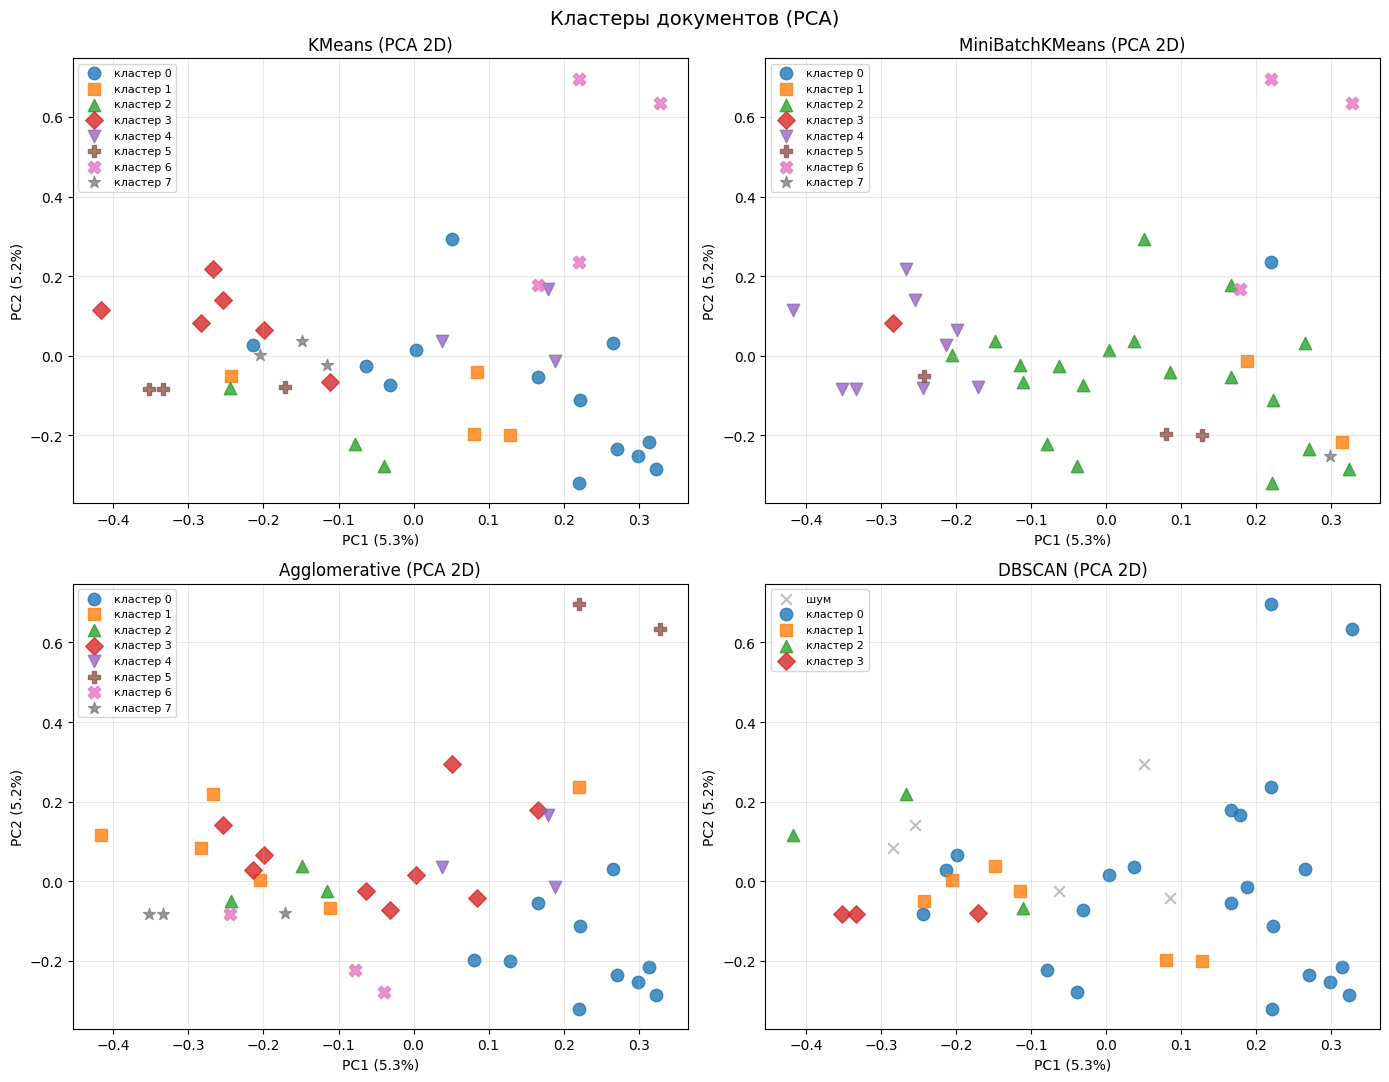

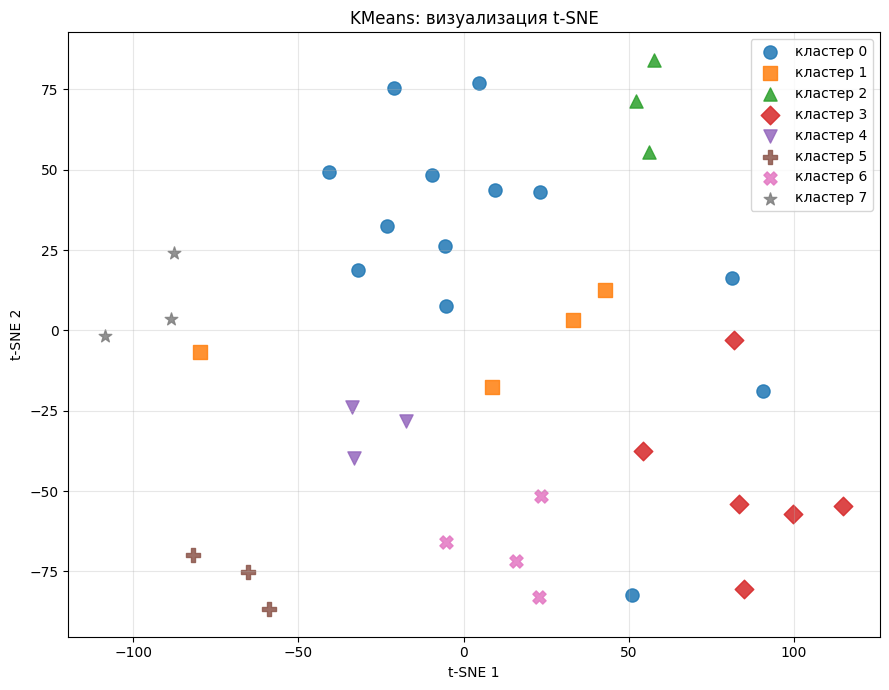

In [61]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns

MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'H', '<']

# PCA до 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for ax, (name, labels) in zip(axes, results.items()):
    unique = sorted(set(labels))
    for cl in unique:
        mask = labels == cl
        if cl == -1:
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                       marker='x', c='gray', s=60, alpha=0.5, label='шум')
        else:
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                       marker=MARKERS[cl % len(MARKERS)],
                       s=80, alpha=0.8, label=f'кластер {cl}')
    ax.set_title(f'{name} (PCA 2D)')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='best')

plt.suptitle('Кластеры документов (PCA)', fontsize=14)
plt.tight_layout()
plt.savefig('clusters_pca.png', dpi=200)
plt.show()

# t-SNE для KMeans
tsne = TSNE(n_components=2, random_state=42, perplexity=10, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X.toarray())

plt.figure(figsize=(9, 7))
labels_km = results['KMeans']
for cl in sorted(set(labels_km)):
    mask = labels_km == cl
    plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                marker=MARKERS[cl % len(MARKERS)],
                s=90, alpha=0.85, label=f'кластер {cl}')
plt.title('KMeans: визуализация t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('clusters_tsne.png', dpi=200)
plt.show()

In [62]:
from collections import Counter

# Таблица: документ кластер для каждого алгоритма
clusters_df = df_clean[['id', 'date', 'clean_text']].copy()
for name, labels in results.items():
    clusters_df[f'cluster_{name}'] = labels
clusters_df.to_csv('clustering_results.csv', index=False, encoding='utf-8-sig')

# Топ-слова по среднему TF-IDF весу для KMeans
terms = vectorizer.get_feature_names_out()
labels_km = results['KMeans']

print("\nТОП-10 слов по кластерам KMeans (по среднему TF-IDF)")
top_terms_rows = []
for cl in sorted(set(labels_km)):
    if cl == -1:
        continue
    mask = labels_km == cl
    weights = X[mask].mean(axis=0).A1  # средний вес TF-IDF по кластеру
    top_idx = np.argsort(weights)[::-1][:10]
    top_words = [terms[i] for i in top_idx]
    print(f"\nКластер {cl} ({mask.sum()} док.):")
    print("  " + ', '.join(top_words))
    top_terms_rows.append({'cluster': cl, 'top_terms': ', '.join(top_words)})

pd.DataFrame(top_terms_rows).to_csv('cluster_top_terms.csv', index=False, encoding='utf-8-sig')

# Примеры постов по кластерам
print("\nПримеры постов по кластерам KMeans")
for cl in sorted(set(labels_km)):
    if cl == -1:
        continue
    sample = clusters_df[clusters_df['cluster_KMeans'] == cl].iloc[0]
    print(f"\nКластер {cl}: {sample['clean_text'][:250]}...")


ТОП-10 слов по кластерам KMeans (по среднему TF-IDF)

Кластер 0 (13 док.):
  университет, программа, студенческий, самарский, участник, развитие, студент, королёв, август, направление

Кластер 1 (4 док.):
  разработка, александр, фетисов, наследие, самара, самарский, объект, авиационный, регион, встреча

Кластер 2 (3 док.):
  команда, проект, соперник, место, эксперт, студент, день, клуб, настоящий, процедура

Кластер 3 (6 док.):
  выпуск, человек, почему, кафедра, казаться, страх, вопрос, ксения, узнать, технология

Кластер 4 (3 док.):
  андрей, экономика, стипендиат, стипендия, студент, правительство, кирилл, полина, лауреат, премия

Кластер 5 (3 док.):
  сад, ботанический, ботсад, открытие, внимание, самарский, август, природа, дата, среди

Кластер 6 (4 док.):
  институт, факультет, международный, олимпиада, ракетный, дмитрий, школа, техника, физика, математический

Кластер 7 (3 док.):
  история, рубрика, психолог, центр, каждый, рубль, деятельность, тяжёлый, продолжать, посвятить
